# GIAI ĐOẠN 3.5: KHÁM PHÁ DỮ LIỆU ĐÁNH GIÁ (EXPLORATORY DATA ANALYSIS - EDA)

## 1. Mục tiêu và Ý nghĩa
- Sau khi dữ liệu đã được làm sạch nhẹ và gán nhãn ở `label.ipynb`, bước **EDA** giúp nhóm và giảng viên quan sát trực quan toàn bộ đặc điểm của bộ dữ liệu trước khi huấn luyện mô hình.
- **Các câu hỏi nghiên cứu EDA giải quyết**:
  1. **Phân bố nhãn cảm xúc**: Tỷ lệ phần trăm và số lượng giữa 3 nhóm (Tiêu cực, Trung tính, Tích cực) có phản ánh đúng thực tế sàn TMĐT không?
  2. **Đặc trưng độ dài câu (Word Count)**: Khách hàng khen thường viết ngắn hay dài? Người chê phàn nàn có chi tiết hơn không?
  3. **Top từ vựng đặc trưng theo từng lớp**: Những từ ngữ nào xuất hiện dày đặc nhất trong nhóm Tiêu cực vs nhóm Tích cực?
- **Đầu ra**: Xuất các biểu đồ trực quan ra thư mục `results/eda/` để chèn trực tiếp vào báo cáo thuyết trình.

### Bước 1: Khai báo thư viện và đọc dữ liệu đã gán nhãn

In [1]:
from collections import Counter
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Cấu hình font chữ và hiển thị tiếng Việt cho matplotlib
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# Thiết lập đường dẫn
SPLIT_DIR = Path("../data/splits")
FIG_DIR   = Path("../results/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Đọc tập dữ liệu huấn luyện (Train) để phân tích đại diện
df_train = pd.read_csv(SPLIT_DIR / "train.csv")

# Bản đồ tên nhãn
LABEL_NAMES = {-1: "Tiêu cực", 0: "Trung tính", 1: "Tích cực"}
df_train["ten_nhan"] = df_train["label"].map(LABEL_NAMES)

print(f"-> Nạp thành công {len(df_train)} dòng từ tập Train để khám phá dữ liệu.")
df_train.head(3)

-> Nạp thành công 601 dòng từ tập Train để khám phá dữ liệu.


,text,label,ten_nhan
0,Hàng xài khá ok,1,Tích cực
1,Máy chán lắm ạ mỗi lần dùng là phải mồi nước m...,-1,Tiêu cực
2,Sản phẩm tốt với tầm giá,1,Tích cực


### Bước 2: Phân tích phân bố các lớp cảm xúc (Class Distribution)

=== BẢNG PHÂN BỐ CÁC LỚP CẢM XÚC ===


,Số lượng,Tỉ lệ (%)
ten_nhan,,
Tích cực,326,54.2
Tiêu cực,140,23.3
Trung tính,135,22.5


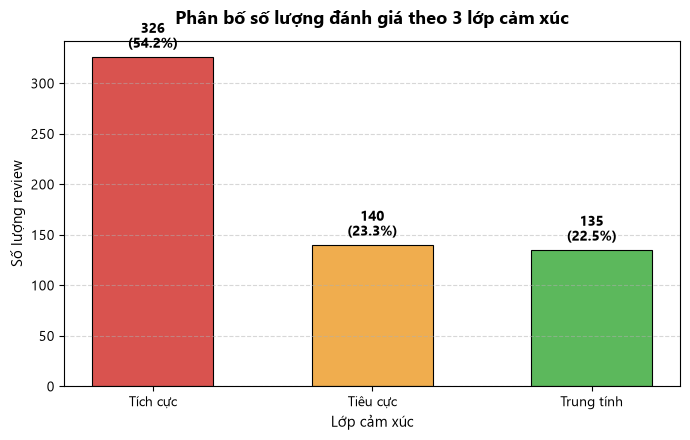

-> Đã lưu ảnh biểu đồ tại: D:\Study\School\k7\code_tay\results\eda\phan_bo_cam_xuc.png


In [2]:
# Đếm số lượng và tỉ lệ phần trăm từng lớp
counts = df_train["ten_nhan"].value_counts()
percentages = df_train["ten_nhan"].value_counts(normalize=True) * 100

df_dist = pd.DataFrame({
    "Số lượng": counts,
    "Tỉ lệ (%)": percentages.round(1)
})
print("=== BẢNG PHÂN BỐ CÁC LỚP CẢM XÚC ===")
display(df_dist)

# Vẽ biểu đồ cột trực quan
fig, ax = plt.subplots(figsize=(7, 4.5))
palette = ["#d9534f", "#f0ad4e", "#5cb85c"]  # Đỏ (Tiêu cực), Vàng (Trung tính), Xanh (Tích cực)

bars = ax.bar(counts.index, counts.values, color=palette, width=0.55, edgecolor="black", linewidth=0.8)
ax.set_title("Phân bố số lượng đánh giá theo 3 lớp cảm xúc", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Số lượng review", fontsize=11)
ax.set_xlabel("Lớp cảm xúc", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)

# Ghi số lượng và % lên đầu mỗi cột
for bar in bars:
    h = bar.get_height()
    pct = (h / len(df_train)) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig(FIG_DIR / "phan_bo_cam_xuc.png", dpi=300)
plt.show()
print(f"-> Đã lưu ảnh biểu đồ tại: {(FIG_DIR / 'phan_bo_cam_xuc.png').resolve()}")

### Bước 3: Phân tích độ dài câu đánh giá (Word Length Analysis)

=== THỐNG KÊ ĐỘ DÀI CÂU THEO LỚP CẢM XÚC ===


,Độ dài TB (từ),Ngắn nhất,Dài nhất,Trung vị
ten_nhan,,,,
Tiêu cực,42.4,3,338,31.5
Trung tính,21.9,2,97,19.0
Tích cực,15.5,1,326,9.0


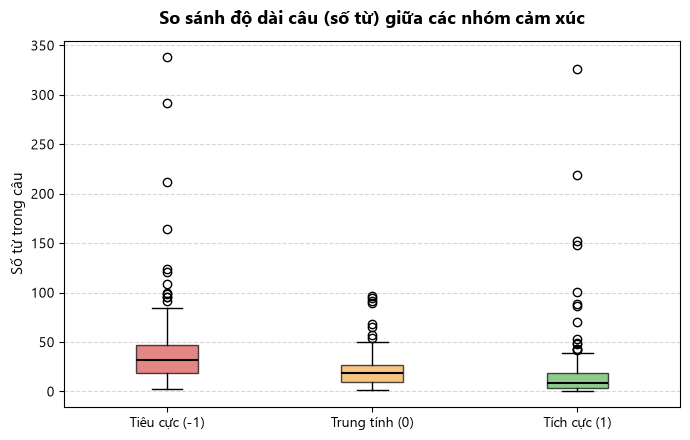

-> Đã lưu ảnh biểu đồ tại: D:\Study\School\k7\code_tay\results\eda\do_dai_cau.png


In [3]:
# Tính số lượng từ trong mỗi câu
df_train["so_tu"] = df_train["text"].astype(str).apply(lambda s: len(s.split()))

# Thống kê độ dài theo từng nhóm cảm xúc
df_len_stat = df_train.groupby("ten_nhan")["so_tu"].agg([
    ("Độ dài TB (từ)", "mean"),
    ("Ngắn nhất", "min"),
    ("Dài nhất", "max"),
    ("Trung vị", "median")
]).round(1)

print("=== THỐNG KÊ ĐỘ DÀI CÂU THEO LỚP CẢM XÚC ===")
display(df_len_stat)

# Vẽ biểu đồ hộp (Boxplot) so sánh độ dài giữa 3 lớp
fig, ax = plt.subplots(figsize=(7, 4.5))
palette = ["#d9534f", "#f0ad4e", "#5cb85c"]
data_to_plot = [df_train[df_train["label"] == l]["so_tu"] for l in [-1, 0, 1]]

box = ax.boxplot(data_to_plot, patch_artist=True, tick_labels=["Tiêu cực (-1)", "Trung tính (0)", "Tích cực (1)"],
                 medianprops=dict(color="black", linewidth=1.5))

for patch, color in zip(box['boxes'], palette):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("So sánh độ dài câu (số từ) giữa các nhóm cảm xúc", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Số từ trong câu", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "do_dai_cau.png", dpi=300)
plt.show()
print(f"-> Đã lưu ảnh biểu đồ tại: {(FIG_DIR / 'do_dai_cau.png').resolve()}")

### Bước 4: Khám phá Top từ vựng xuất hiện nhiều nhất theo từng lớp cảm xúc

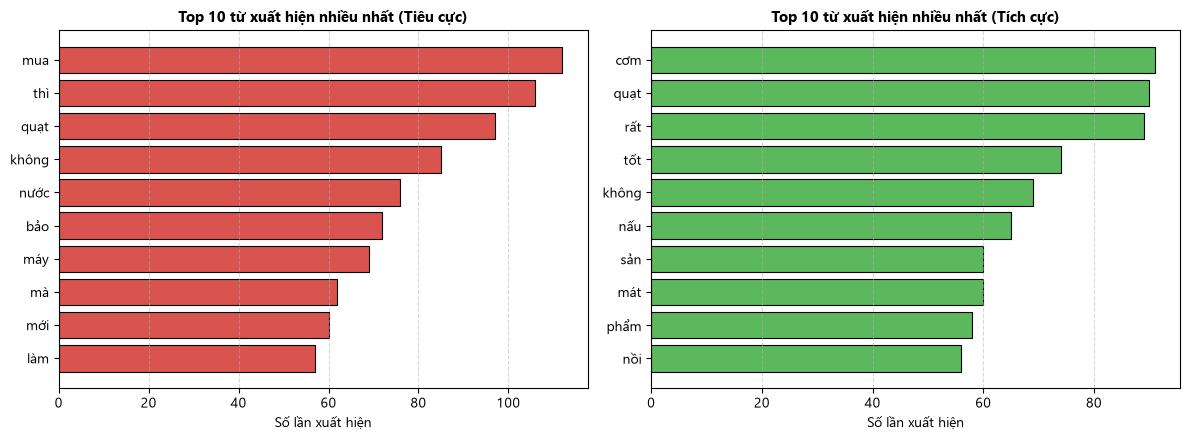

-> Đã lưu ảnh biểu đồ tại: D:\Study\School\k7\code_tay\results\eda\top_tu_vung.png


In [4]:
# Hàm lấy top từ vựng phổ biến
def lay_top_tu(texts: pd.Series, top_k: int = 10):
    words = []
    for t in texts:
        for w in str(t).lower().split():
            if len(w) > 1:  # Bỏ qua ký tự 1 chữ cái đơn lẻ
                words.append(w)
    return Counter(words).most_common(top_k)

# Trích xuất Top từ vựng cho Tiêu cực và Tích cực
top_tieu_cuc = lay_top_tu(df_train[df_train["label"] == -1]["text"], 10)
top_tich_cuc = lay_top_tu(df_train[df_train["label"] == 1]["text"], 10)

# Vẽ biểu đồ so sánh Top từ ngữ đặc trưng
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Tiêu cực
tu_tc, dem_tc = zip(*reversed(top_tieu_cuc))
ax1.barh(tu_tc, dem_tc, color="#d9534f", edgecolor="black", linewidth=0.8)
ax1.set_title("Top 10 từ xuất hiện nhiều nhất (Tiêu cực)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Số lần xuất hiện")
ax1.grid(axis="x", linestyle="--", alpha=0.5)

# 2. Tích cực
tu_pos, dem_pos = zip(*reversed(top_tich_cuc))
ax2.barh(tu_pos, dem_pos, color="#5cb85c", edgecolor="black", linewidth=0.8)
ax2.set_title("Top 10 từ xuất hiện nhiều nhất (Tích cực)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Số lần xuất hiện")
ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "top_tu_vung.png", dpi=300)
plt.show()
print(f"-> Đã lưu ảnh biểu đồ tại: {(FIG_DIR / 'top_tu_vung.png').resolve()}")